# Data loading

In [9]:
from pathlib import Path
import re
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.transform import from_origin
from pyresample import geometry, kd_tree
import matplotlib.pyplot as plt

DATA = Path("../data")
OUT = Path("../outputs"); OUT.mkdir(exist_ok=True)

STRIPS = ["M3G20090205T111013", "M3G20090205T092400"]   # primary strip first

# Apollo 15 landing site and subset box (degrees)
SITE_LAT, SITE_LON = 26.132, 3.634
LAT_MIN, LAT_MAX = 25.4, 26.9
LON_MIN, LON_MAX = 2.8, 4.05     # tightened to what the primary strip fully covers
RES = 0.0045                     # output grid, ~140 m/pixel

def find(strip, kind, ext="img"):
    """Locate e.g. the RFL .IMG for a strip anywhere under data/."""
    hits = [p for p in DATA.rglob(f"{strip}_*_{kind}.*")
            if p.suffix.lower() == f".{ext}"]
    if not hits:
        raise FileNotFoundError(f"{strip} {kind}.{ext} not found in {DATA}")
    return hits[0]

In [10]:
for strip in STRIPS:
    print(strip)
    for kind in ["RFL", "SUP", "LOC", "OBS"]:
        with rasterio.open(find(strip, kind)) as src:
            print(f"  {kind}: bands={src.count:3d}  lines={src.height}  "
                  f"samples={src.width}  dtype={src.dtypes[0]}")

M3G20090205T111013
  RFL: bands= 85  lines=13822  samples=304  dtype=float32
  SUP: bands=  3  lines=13822  samples=304  dtype=float32
  LOC: bands=  3  lines=13822  samples=304  dtype=float64
  OBS: bands= 10  lines=13822  samples=304  dtype=float32
M3G20090205T092400
  RFL: bands= 85  lines=13197  samples=304  dtype=float32
  SUP: bands=  3  lines=13197  samples=304  dtype=float32
  LOC: bands=  3  lines=13197  samples=304  dtype=float64
  OBS: bands= 10  lines=13197  samples=304  dtype=float32


/Users/sourabh/Documents/python_codes/m3_spectral_clustering/.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [11]:
def read_wavelengths(strip):
    text = find(strip, "RFL", ext="hdr").read_text()
    m = re.search(r"wavelength\s*=\s*\{([^}]*)\}", text, re.I)
    return np.array([float(v) for v in m.group(1).split(",")])

wl = read_wavelengths(STRIPS[0])
print(len(wl), "bands:", wl[0], "to", wl[-1])

85 bands: 460.99 to 2976.2


# Subset image to Mons Hadley

In [12]:
def load_subset(strip):
    with rasterio.open(find(strip, "LOC")) as src:
        lon, lat = src.read(1), src.read(2)
    lon = ((lon + 180) % 360) - 180                 # force -180..180

    in_box = (lat > LAT_MIN) & (lat < LAT_MAX) & (lon > LON_MIN) & (lon < LON_MAX)
    rows = np.where(in_box.any(axis=1))[0]
    if rows.size == 0:
        print(f"{strip}: does not cross the box")
        return None
    r0, r1 = rows.min(), rows.max() + 1
    win = Window(0, r0, lon.shape[1], r1 - r0)       # col_off, row_off, width, height

    with rasterio.open(find(strip, "RFL")) as src:
        rfl = src.read(window=win)                   # (85, lines, 304)
    with rasterio.open(find(strip, "OBS")) as src:
        obs = src.read(window=win)                   # (10, lines, 304)
    rfl = np.where(rfl < -900, np.nan, rfl)          # -999 = no data

    lon, lat = lon[r0:r1], lat[r0:r1]
    d_km = np.hypot(lat - SITE_LAT,
                    (lon - SITE_LON) * np.cos(np.radians(SITE_LAT))).min() * 30.3
    print(f"{strip}: lines {r0}-{r1}, rfl {rfl.shape}, "
          f"nearest pixel to landing site = {d_km:.2f} km")
    return dict(strip=strip, lon=lon, lat=lat, rfl=rfl, obs=obs)

subsets = [s for s in (load_subset(s) for s in STRIPS) if s is not None]

M3G20090205T111013: lines 12274-12571, rfl (85, 297, 304), nearest pixel to landing site = 0.03 km
M3G20090205T092400: lines 5294-5591, rfl (85, 297, 304), nearest pixel to landing site = 0.04 km


/Users/sourabh/Documents/python_codes/m3_spectral_clustering/.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Statistics window: lines 10274-13822  shape (85, 3548, 304)
bad element: band  3 ( 580.8 nm), column 160
bad element: band  4 ( 620.7 nm), column 166
bad element: band  9 ( 770.4 nm), column 191
bad element: band  9 ( 770.4 nm), column 200
bad element: band 10 ( 790.4 nm), column 294
bad element: band 11 ( 810.3 nm), column 250
bad element: band 11 ( 810.3 nm), column 294
bad element: band 12 ( 830.3 nm), column 90
bad element: band 12 ( 830.3 nm), column 111
bad element: band 12 ( 830.3 nm), column 250
bad element: band 13 ( 850.2 nm), column 58
bad element: band 13 ( 850.2 nm), column 193
bad element: band 14 ( 870.2 nm), column 113
bad element: band 15 ( 890.2 nm), column 200
bad element: band 15 ( 890.2 nm), column 272
bad element: band 15 ( 890.2 nm), column 274
bad element: band 16 ( 910.1 nm), column 18
bad element: band 17 ( 930.1 nm), column 52
bad element: band 18 ( 950.1 nm), column 222
bad element: band 20 ( 990.0 nm), column 198
bad element: band 24 (1069.8 nm), column 212

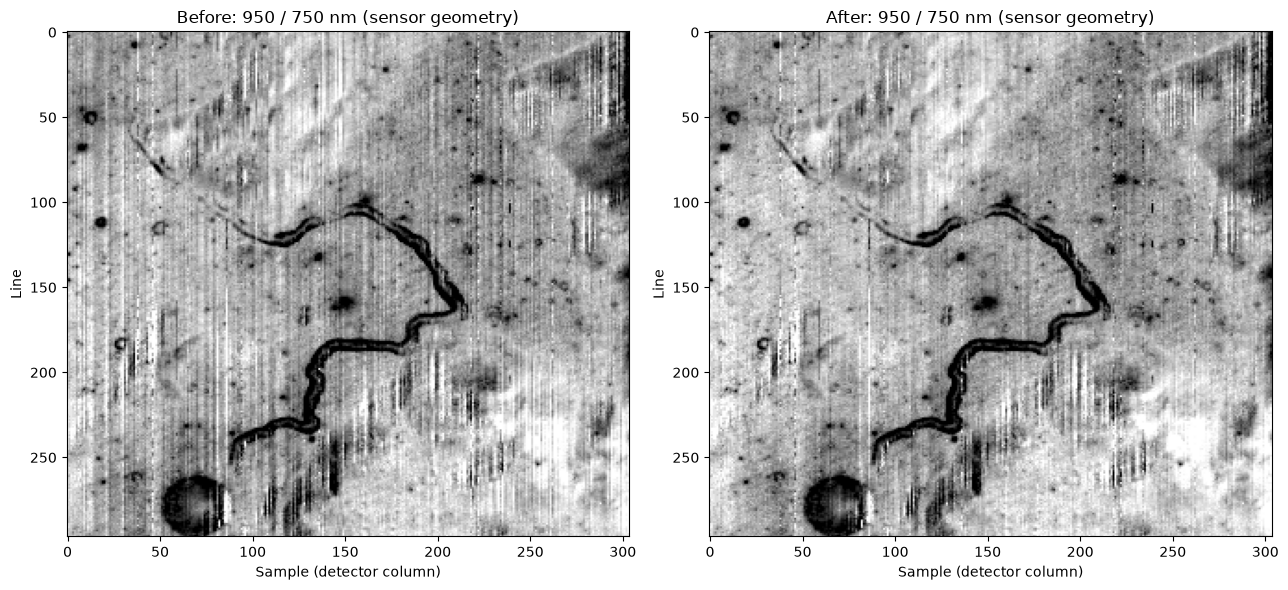

In [90]:
from scipy.ndimage import median_filter, uniform_filter1d

PAD = 2000                                           # extra lines above and below the box
strip = subsets[0]["strip"]

with rasterio.open(find(strip, "LOC")) as src:
    lon, lat = src.read(1), src.read(2)
lon = ((lon + 180) % 360) - 180
in_box = (lat > LAT_MIN) & (lat < LAT_MAX) & (lon > LON_MIN) & (lon < LON_MAX)
rows = np.where(in_box.any(axis=1))[0]
r0, r1 = rows.min(), rows.max() + 1
w0, w1 = max(r0 - PAD, 0), min(r1 + PAD, lat.shape[0])

with rasterio.open(find(strip, "RFL")) as src:
    wide = src.read(window=Window(0, w0, src.width, w1 - w0)).astype("float32")
wide[wide < -900] = np.nan
nb, nl, ns = wide.shape
print(f"Statistics window: lines {w0}-{w1}  shape {wide.shape}")

b750 = np.argmin(np.abs(wl - 750))
dark = ~(wide[b750] > 0.02)                          # shadow / no-data, excluded from statistics
before = wide[:, r0 - w0:r1 - w0, :].copy()          # box subset before correction (for the check)



THRESH = 1.5                                         # flag columns this many times noisier than typical

bad = np.zeros((nb, ns), bool)
for i in range(nb):
    v = np.where(dark, np.nan, wide[i])
    if np.isnan(v).all():
        continue                                     # empty band (0 and 1)
    resid = v[:, 1:-1] - 0.5 * (v[:, :-2] + v[:, 2:])   # column minus mean of its neighbours
    noise = np.full(ns, np.nan)
    noise[1:-1] = np.nanstd(resid, axis=0)
    flagged = noise > THRESH * np.nanmedian(noise)
    # a bad column also inflates its two neighbours: keep only the local peak
    peak = (noise >= np.roll(noise, 1)) & (noise >= np.roll(noise, -1))
    bad[i] = flagged & peak

for i, c in zip(*np.where(bad)):
    print(f"bad element: band {i:2d} ({wl[i]:6.1f} nm), column {c}")
print("Total bad elements:", bad.sum())

cols = np.arange(ns)
for i in np.where(bad.any(axis=1))[0]:
    good = ~bad[i]
    for c in np.where(bad[i])[0]:
        l = cols[good & (cols < c)].max()            # nearest good column on each side
        r = cols[good & (cols > c)].min()
        wgt = (c - l) / (r - l)
        wide[i, :, c] = (1 - wgt) * wide[i, :, l] + wgt * wide[i, :, r]




PAD_LOCAL = 300                                      # lines above/below the box used for the fit
a0 = max(r0 - w0 - PAD_LOCAL, 0)
a1 = min(r1 - w0 + PAD_LOCAL, nl)
loc = wide[:, a0:a1, :]                              # view into `wide`, edited in place
dk = dark[a0:a1]

gains, offsets = np.ones((nb, ns)), np.zeros((nb, ns))
for i in range(nb):
    v = loc[i]
    if np.isnan(v).all():
        continue
    filled = np.where(np.isfinite(v), v, np.nanmedian(v))
    s = median_filter(filled, size=(1, 9), mode="nearest")   # stripe-free estimate, per line

    ok = ~dk & np.isfinite(v)                        # fit on sunlit, valid pixels only
    n_ok = np.maximum(ok.sum(axis=0), 1)
    sm = np.where(ok, s, 0).sum(axis=0) / n_ok
    vm = np.where(ok, v, 0).sum(axis=0) / n_ok
    cov = np.where(ok, (s - sm) * (v - vm), 0).sum(axis=0) / n_ok
    var = np.where(ok, (s - sm) ** 2, 0).sum(axis=0) / n_ok

    a = np.clip(cov / np.maximum(var, 1e-12), 0.8, 1.25)     # per-column gain
    o = vm - a * sm                                          # per-column offset
    loc[i] = (v - o) / a
    gains[i], offsets[i] = a, o

print(f"Gain spread (std), median over bands:   {np.median(gains.std(axis=1)) * 100:.2f}%")
print(f"Offset spread (std), median over bands: {np.median(offsets.std(axis=1)):.5f} reflectance")

if "rfl_original" not in subsets[0]:
    subsets[0]["rfl_original"] = subsets[0]["rfl"]
subsets[0]["rfl"] = wide[:, r0 - w0:r1 - w0, :].copy()



b950 = np.argmin(np.abs(wl - 950))
after = subsets[0]["rfl"]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, data, title in zip(axes, [before, after], ["Before", "After"]):
    ratio = data[b950] / data[b750]
    ax.imshow(ratio, cmap="gray", vmin=np.nanpercentile(ratio, 2),
              vmax=np.nanpercentile(ratio, 98), aspect="auto")
    ax.set_title(f"{title}: {wl[b950]:.0f} / {wl[b750]:.0f} nm (sensor geometry)")
    ax.set_xlabel("Sample (detector column)"); ax.set_ylabel("Line")
plt.tight_layout(); plt.show()

# Georeferencing (Save files)

In [91]:
MOON = {"proj": "longlat", "R": 1737400, "no_defs": True}
WIDTH  = int(round((LON_MAX - LON_MIN) / RES))
HEIGHT = int(round((LAT_MAX - LAT_MIN) / RES))
AREA = geometry.AreaDefinition("a15", "", "", MOON, WIDTH, HEIGHT,
                               (LON_MIN, LAT_MIN, LON_MAX, LAT_MAX))

# pyresample measures search distances on an Earth-sized sphere,
# so scale the lunar radius up by R_earth / R_moon (~3.67)
EARTH_R, MOON_R = 6370997.0, 1737400.0
RADIUS = 200 * EARTH_R / MOON_R      # 200 m on the Moon

def georeference(sub, key="rfl"):
    swath = geometry.SwathDefinition(lons=sub["lon"], lats=sub["lat"])
    data = np.moveaxis(sub[key], 0, -1)              # (lines, samples, bands)
    out = kd_tree.resample_nearest(swath, data, AREA,
                                   radius_of_influence=RADIUS, fill_value=np.nan)
    return np.moveaxis(out, -1, 0).astype("float32") # (bands, HEIGHT, WIDTH)

def save_geotiff(cube, path):
    with rasterio.open(path, "w", driver="GTiff", width=WIDTH, height=HEIGHT,
                       count=cube.shape[0], dtype="float32", nodata=np.nan,
                       crs="+proj=longlat +R=1737400 +no_defs",
                       transform=from_origin(LON_MIN, LAT_MAX, RES, RES)) as dst:
        dst.write(cube)

for sub in subsets:
    sub["rfl_geo"] = georeference(sub, "rfl")
    save_geotiff(sub["rfl_geo"], OUT / f"{sub['strip']}_a15_rfl.tif")
    print(sub["strip"], sub["rfl_geo"].shape)

M3G20090205T111013 (85, 333, 278)
M3G20090205T092400 (85, 333, 278)


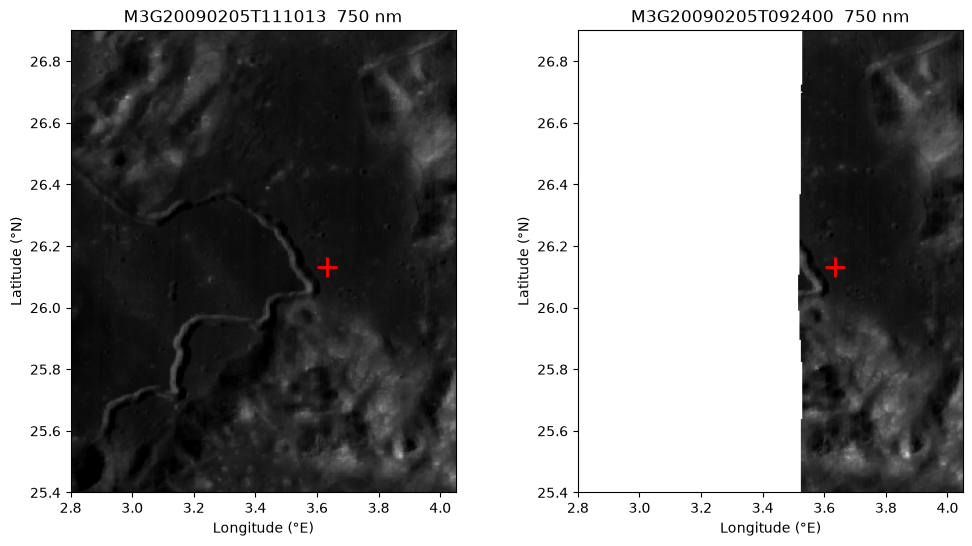

In [78]:
b = np.argmin(np.abs(wl - 750))                      # ~750 nm band
fig, axes = plt.subplots(1, len(subsets), figsize=(6 * len(subsets), 6), squeeze=False)
for ax, sub in zip(axes[0], subsets):
    ax.imshow(sub["rfl_geo"][b], cmap="gray",
              extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX), vmin=0.03, vmax=0.20)
    ax.plot(SITE_LON, SITE_LAT, "r+", ms=14, mew=2)
    ax.set_title(f"{sub['strip']}  {wl[b]:.0f} nm")
    ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
plt.show()

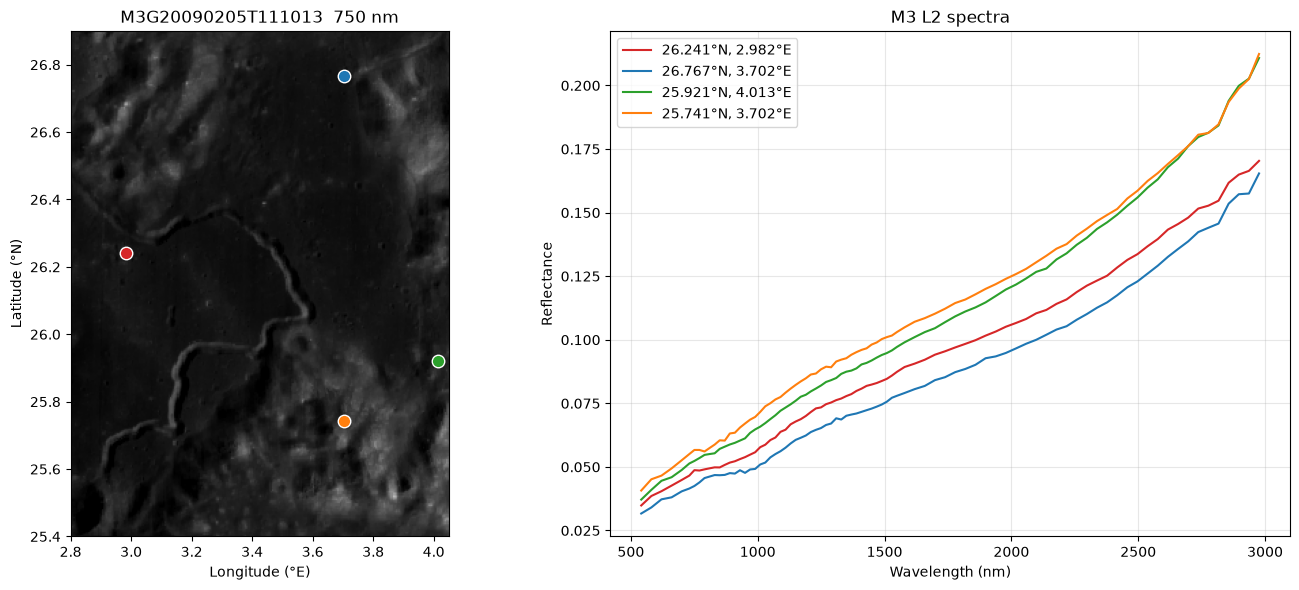

In [79]:
cube = subsets[0]["rfl_geo"]                         # (bands, HEIGHT, WIDTH), primary strip
valid = np.isfinite(cube[b]) & (cube[b] > 0)
rng = np.random.default_rng(42)                      # change or remove the seed for new points
rows, cols = np.where(valid)
pick = rng.choice(rows.size, size=4, replace=False)
rows, cols = rows[pick], cols[pick]
lons = LON_MIN + (cols + 0.5) * RES
lats = LAT_MAX - (rows + 0.5) * RES

colors = ["tab:red", "tab:blue", "tab:green", "tab:orange"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.imshow(cube[b], cmap="gray", vmin=0.03, vmax=0.20,
           extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax1.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
for i in range(4):
    ax1.plot(lons[i], lats[i], "o", color=colors[i], ms=9, mec="white")
ax1.set_xlabel("Longitude (°E)"); ax1.set_ylabel("Latitude (°N)")
ax1.set_title(f"{subsets[0]['strip']}  {wl[b]:.0f} nm")

for i in range(4):
    ax2.plot(wl, cube[:, rows[i], cols[i]], color=colors[i],
             label=f"{lats[i]:.3f}°N, {lons[i]:.3f}°E")
ax2.set_xlabel("Wavelength (nm)"); ax2.set_ylabel("Reflectance")
ax2.set_title("M3 L2 spectra")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [80]:
empty = np.where(np.isnan(cube).all(axis=(1, 2)))[0]
print("All-NaN bands:", empty, "→ wavelengths:", wl[empty])

All-NaN bands: [0 1] → wavelengths: [460.99 500.92]


# Data Cleaning

In [92]:
cube = subsets[0]["rfl_geo"]
footprint = np.isfinite(cube[b])                     # pixels inside the strip
n = footprint.sum()

print(f"{'band':>4} {'wl(nm)':>8} {'NaN%':>7} {'<=0 %':>7} {'>1 %':>6} {'min':>8} {'max':>8}")
for i in range(cube.shape[0]):
    v = cube[i][footprint]
    nan = np.isnan(v).mean() * 100
    f = v[np.isfinite(v)]
    if f.size == 0:
        print(f"{i:4d} {wl[i]:8.1f} {nan:7.2f}   (empty band)")
        continue
    neg, hi = (f <= 0).mean() * 100, (f > 1).mean() * 100
    if nan > 0 or neg > 0 or hi > 0:                 # only print bands with a problem
        print(f"{i:4d} {wl[i]:8.1f} {nan:7.2f} {neg:7.2f} {hi:6.2f} {f.min():8.4f} {f.max():8.4f}")

band   wl(nm)    NaN%   <=0 %   >1 %      min      max
   0    461.0  100.00   (empty band)
   1    500.9  100.00   (empty band)


In [93]:
# 1. drop bands that are entirely empty
good = ~np.isnan(cube[:, footprint]).all(axis=1)
cube_c, wl_c = cube[good].copy(), wl[good]

# 2. set physically impossible values to NaN
cube_c[(cube_c <= 0) | (cube_c > 1)] = np.nan

# 3. mask pixels that are shadowed or have any remaining bad band
b_c = np.argmin(np.abs(wl_c - 750))
mask = footprint & np.isfinite(cube_c).all(axis=0) & (cube_c[b_c] > 0.04)

print(f"Bands kept: {cube_c.shape[0]} of {cube.shape[0]}")
print(f"Pixels kept: {mask.sum()} of {n} ({mask.sum() / n * 100:.1f}%)")

Bands kept: 83 of 85
Pixels kept: 78131 of 92574 (84.4%)


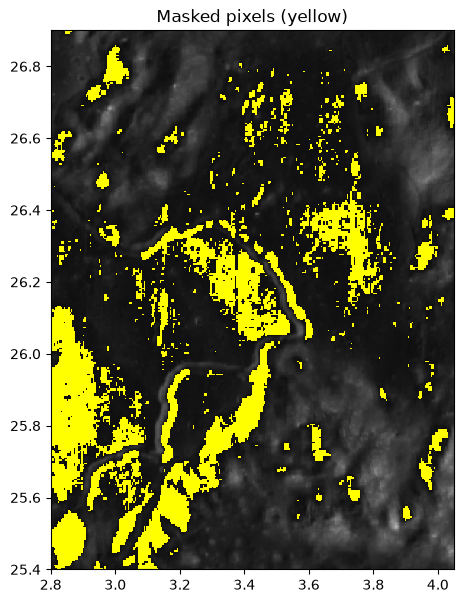

In [100]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(cube_c[b_c], cmap="gray", vmin=0.03, vmax=0.20,
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.imshow(np.where(footprint & ~mask, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1,
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX), interpolation="nearest")
ax.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
ax.set_title("Masked pixels (yellow)")
plt.show()

Sample columns with band-3 values <= 0: []


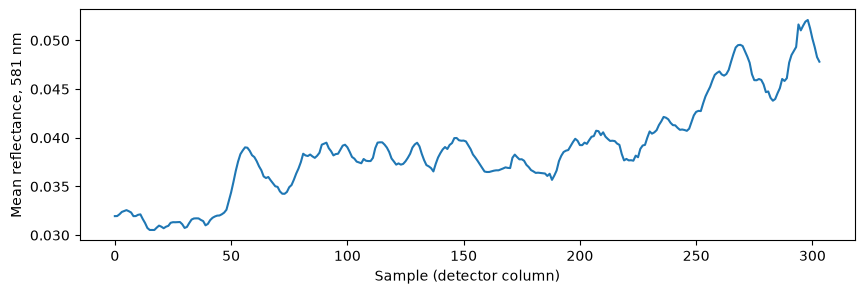

In [101]:
raw = subsets[0]["rfl"]                              # (85, lines, 304), sensor geometry
neg_cols = np.where((raw[3] <= 0).any(axis=0))[0]
print("Sample columns with band-3 values <= 0:", neg_cols)

col_mean = np.nanmean(raw[3], axis=0)                # mean of band 3 along each column
plt.figure(figsize=(10, 3))
plt.plot(col_mean)
for c in neg_cols:
    plt.axvline(c, color="r", alpha=0.3)
plt.xlabel("Sample (detector column)"); plt.ylabel("Mean reflectance, 581 nm")
plt.show()

In [102]:
raw = subsets[0]["rfl"]
c = int(neg_cols[0])

# band 3: noise of every column relative to its neighbours
resid = raw[3, :, 1:-1] - 0.5 * (raw[3, :, :-2] + raw[3, :, 2:])
plt.figure(figsize=(10, 3))
plt.plot(np.arange(1, raw.shape[2] - 1), np.nanstd(resid, axis=0))
plt.axvline(c, color="r", alpha=0.3)
plt.xlabel("Sample (detector column)"); plt.ylabel("Std of residual, 581 nm")
plt.show()

# column c: same measure for every band, to see if other wavelengths are affected
resid_c = raw[:, :, c] - 0.5 * (raw[:, :, c - 1] + raw[:, :, c + 1])
plt.figure(figsize=(10, 3))
plt.plot(wl, np.nanstd(resid_c, axis=1), "o-")
plt.xlabel("Wavelength (nm)"); plt.ylabel(f"Std of residual, column {c}")
plt.show()

IndexError: index 0 is out of bounds for axis 0 with size 0

In [103]:
# 1. keep 620–2500 nm (drops empty bands 0–1, noisy 541/581 nm, and the thermal/3 µm end)
keep = (wl >= 620) & (wl <= 2500)
cube_c, wl_c = cube[keep].copy(), wl[keep]

# 2. set physically impossible values to NaN
cube_c[(cube_c <= 0) | (cube_c > 1)] = np.nan

# 3. mask shadowed pixels and any pixel with a remaining bad band
b_c = np.argmin(np.abs(wl_c - 750))
mask = footprint & np.isfinite(cube_c).all(axis=0) & (cube_c[b_c] > 0.02)

print(f"Bands kept: {cube_c.shape[0]} of {cube.shape[0]}  "
      f"({wl_c[0]:.0f}–{wl_c[-1]:.0f} nm)")
print(f"Pixels kept: {mask.sum()} of {n} ({mask.sum() / n * 100:.1f}%)")

Bands kept: 69 of 85  (621–2497 nm)
Pixels kept: 92494 of 92574 (99.9%)


# Input Data Prep

In [104]:
X = cube_c[:, mask].T        # (92422 pixels, 69 bands), ready for clustering or unmixing

# Clustering with Agglomerative ward clustering with KNN assistance

In [105]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, fcluster

X = cube_c[:, mask].T                                # (pixels, bands)
Xz = StandardScaler().fit_transform(X)               # column-wise z-score

conn = kneighbors_graph(Xz, n_neighbors=15, include_self=False, n_jobs=-1)

ward = AgglomerativeClustering(n_clusters=None, distance_threshold=0,
                               linkage="ward", connectivity=conn,
                               compute_full_tree=True).fit(Xz)

# build a scipy-style linkage matrix from the fitted tree
n_samples = Xz.shape[0]
counts = np.zeros(ward.children_.shape[0])
for i, (left, right) in enumerate(ward.children_):
    counts[i] = ((1 if left < n_samples else counts[left - n_samples]) +
                 (1 if right < n_samples else counts[right - n_samples]))
dist = np.maximum.accumulate(ward.distances_)        # enforce non-decreasing merges
Z = np.column_stack([ward.children_, dist, counts]).astype(float)

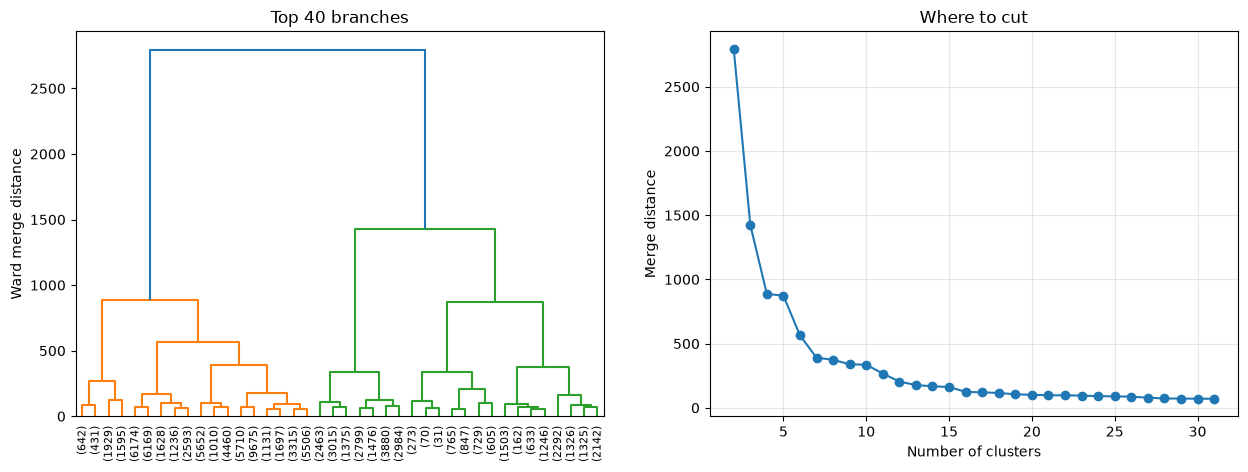

In [106]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z, truncate_mode="lastp", p=40, show_leaf_counts=True,
           leaf_rotation=90, ax=ax1)
ax1.set_ylabel("Ward merge distance"); ax1.set_title("Top 40 branches")

last = Z[-30:, 2][::-1]                              # last 30 merges, largest first
ax2.plot(np.arange(2, 32), last, "o-")
ax2.set_xlabel("Number of clusters"); ax2.set_ylabel("Merge distance")
ax2.set_title("Where to cut"); ax2.grid(alpha=0.3)
plt.show()

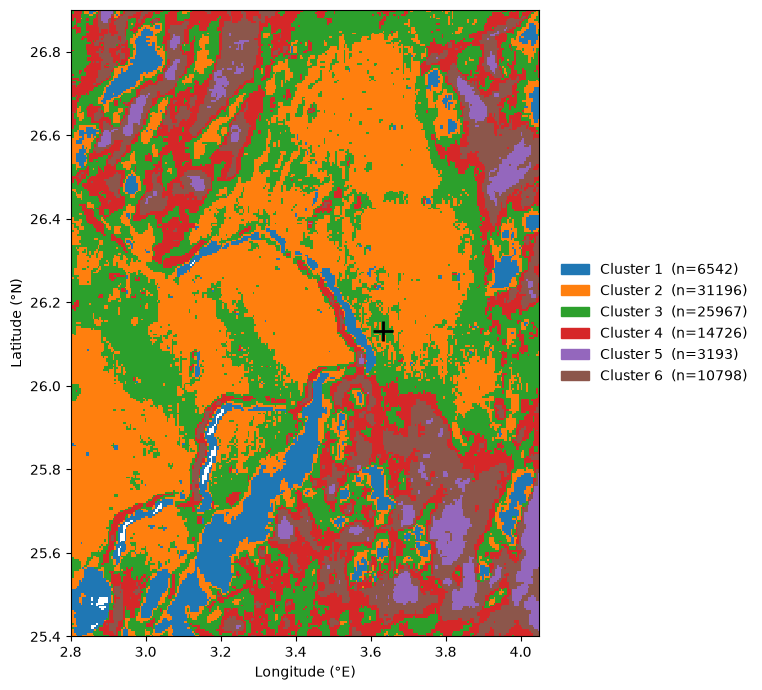

In [107]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

k = int(labels.max())
colors = plt.get_cmap("tab10").colors[:k] if k <= 10 else plt.get_cmap("tab20").colors[:k]
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(0.5, k + 1.5), k)      # one bin per integer label

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(label_img, cmap=cmap, norm=norm, interpolation="nearest",
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
ax.plot(SITE_LON, SITE_LAT, "k+", ms=14, mew=2)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")

sizes = np.bincount(labels, minlength=k + 1)[1:]
handles = [Patch(color=colors[i], label=f"Cluster {i + 1}  (n={sizes[i]})")
           for i in range(k)]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout(); plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 92494 but size of corresponding boolean axis is 92422

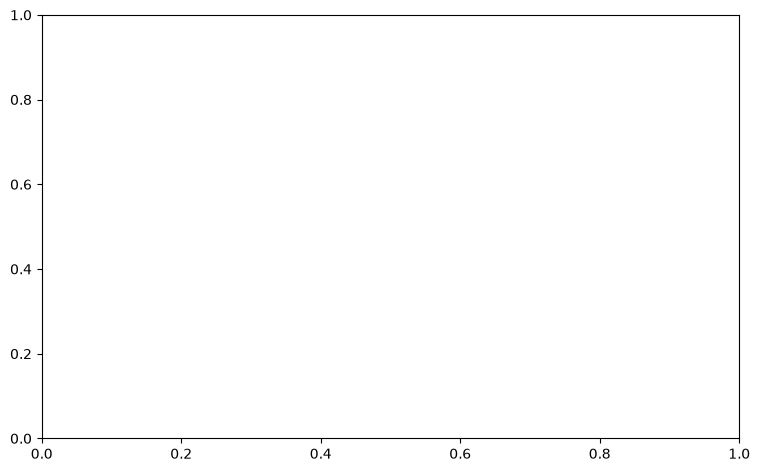

In [108]:
fig, ax = plt.subplots(figsize=(9, 5.5))

for i in range(k):
    spec = X[labels == i + 1]                        # reflectance, not z-scores
    mean, std = spec.mean(axis=0), spec.std(axis=0)
    ax.plot(wl_c, mean, color=colors[i], lw=2, label=f"Cluster {i + 1}  (n={len(spec)})")
    ax.fill_between(wl_c, mean - std, mean + std, color=colors[i], alpha=0.15)

ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance")
ax.set_title("Cluster mean spectra (shading = ±1 std)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
def continuum_removed(wl, R):
    """Divide each spectrum (row of R) by its upper convex hull."""
    out = np.empty_like(R)
    for j, y in enumerate(R):
        hull = []                                    # indices of hull points
        for i in range(len(wl)):
            while len(hull) >= 2:
                i1, i2 = hull[-2], hull[-1]
                cross = ((wl[i2] - wl[i1]) * (y[i] - y[i1]) -
                         (y[i2] - y[i1]) * (wl[i] - wl[i1]))
                if cross >= 0:                       # i2 lies on or below the line i1→i
                    hull.pop()
                else:
                    break
            hull.append(i)
        out[j] = y / np.interp(wl, wl[hull], y[hull])
    return out

X_cr = continuum_removed(wl_c, X)                    # (92422 pixels, 69 bands)
print(X_cr.shape, "range:", X_cr.min().round(3), "to", X_cr.max().round(3))

(92494, 69) range: 0.499 to 1.0


IndexError: boolean index did not match indexed array along axis 0; size of axis is 92494 but size of corresponding boolean axis is 92422

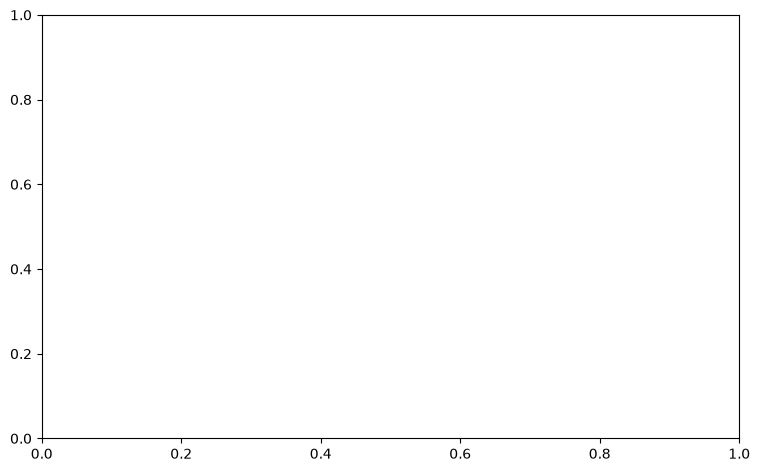

In [109]:
fig, ax = plt.subplots(figsize=(9, 5.5))

for i in range(k):
    spec = X_cr[labels == i + 1]
    mean, std = spec.mean(axis=0), spec.std(axis=0)
    ax.plot(wl_c, mean, color=colors[i], lw=2, label=f"Cluster {i + 1}  (n={len(spec)})")
    ax.fill_between(wl_c, mean - std, mean + std, color=colors[i], alpha=0.15)

ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Continuum-removed reflectance")
ax.set_title("Continuum-removed cluster spectra (mean ± 1 std)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Continuum removal based clustering

In [110]:
# continuum removal pins the first and last band to exactly 1.0 for every pixel,
# so those columns have zero variance and carry no information: drop them
var_ok = X_cr.std(axis=0) > 1e-6
print("Bands dropped (zero variance):", wl_c[~var_ok])
wl_cr = wl_c[var_ok]

# centre each band but do NOT scale: deep absorption bands keep their natural weight
Xz_cr = X_cr[:, var_ok] - X_cr[:, var_ok].mean(axis=0)

conn_cr = kneighbors_graph(Xz_cr, n_neighbors=15, include_self=False, n_jobs=-1)

ward_cr = AgglomerativeClustering(n_clusters=None, distance_threshold=0,
                                  linkage="ward", connectivity=conn_cr,
                                  compute_full_tree=True).fit(Xz_cr)

def linkage_from_model(model, n_samples):
    """Build a scipy-style linkage matrix from a fitted AgglomerativeClustering."""
    counts = np.zeros(model.children_.shape[0])
    for i, (left, right) in enumerate(model.children_):
        counts[i] = ((1 if left < n_samples else counts[left - n_samples]) +
                     (1 if right < n_samples else counts[right - n_samples]))
    dist = np.maximum.accumulate(model.distances_)        # enforce non-decreasing merges
    return np.column_stack([model.children_, dist, counts]).astype(float)

Z_cr = linkage_from_model(ward_cr, Xz_cr.shape[0])
print("Largest merge distances:", np.round(Z_cr[-8:, 2][::-1], 3))

Bands dropped (zero variance): [ 620.69 2497.11]
Largest merge distances: [41.686 21.316 20.399 18.765 11.582  9.698  8.867  8.407]


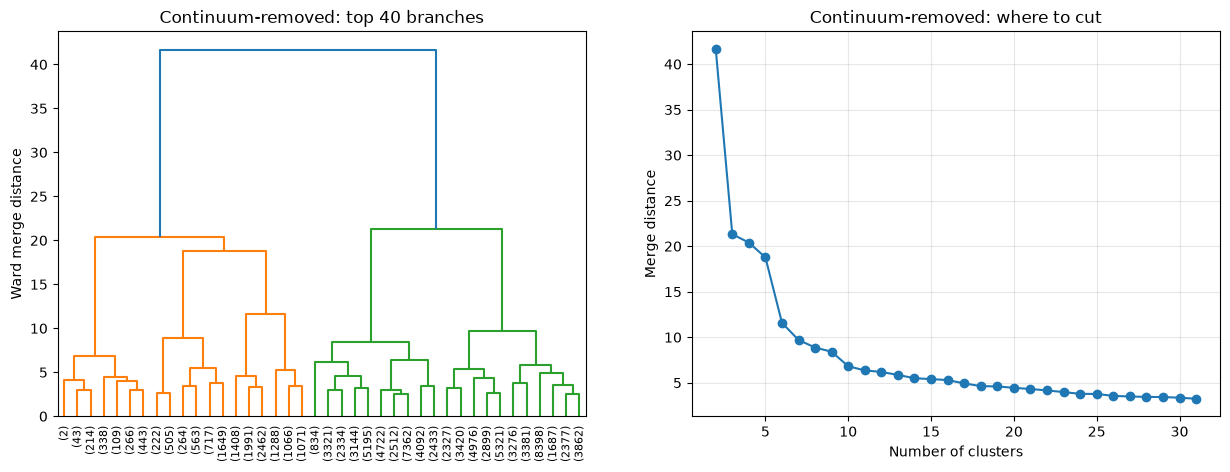

In [111]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z_cr, truncate_mode="lastp", p=40, show_leaf_counts=True,
           leaf_rotation=90, ax=ax1)
ax1.set_ylabel("Ward merge distance")
ax1.set_title("Continuum-removed: top 40 branches")

last = Z_cr[-30:, 2][::-1]                                # last 30 merges, largest first
ax2.plot(np.arange(2, 32), last, "o-")
ax2.set_xlabel("Number of clusters"); ax2.set_ylabel("Merge distance")
ax2.set_title("Continuum-removed: where to cut"); ax2.grid(alpha=0.3)
plt.show()

In [114]:
CUT_CR = 5                                             # set from the Cell 17 dendrogram
#N_CLUSTERS_CR = 8                                         # used only while CUT_CR is None

if CUT_CR is not None:
    labels_cr = fcluster(Z_cr, t=CUT_CR, criterion="distance")
else:
    labels_cr = fcluster(Z_cr, t=N_CLUSTERS_CR, criterion="maxclust")

k_cr = int(labels_cr.max())
print("Clusters:", k_cr, " sizes:", np.bincount(labels_cr)[1:])

label_img_cr = np.full(mask.shape, np.nan)
label_img_cr[mask] = labels_cr

Clusters: 16  sizes: [  259  1156   727   827  2366  5861  1288  2137   834 13994 14596  6525
  5747 13196  6657 16324]


In [125]:
import matplotlib.patheffects as pe

KM_PER_DEG = np.pi * 1737.4 / 180                    # ~30.32 km per degree on the Moon

def add_scalebar(ax, km=5, pad=0.05):
    """Draw a horizontal scale bar of length `km` in the lower-right corner."""
    length_deg = km / (KM_PER_DEG * np.cos(np.radians(SITE_LAT)))   # degrees of longitude
    x1 = LON_MAX - pad * (LON_MAX - LON_MIN)
    x0 = x1 - length_deg
    y = LAT_MIN + pad * (LAT_MAX - LAT_MIN)
    outline = [pe.withStroke(linewidth=4, foreground="black")]
    ax.plot([x0, x1], [y, y], color="white", lw=2.5, solid_capstyle="butt",
            path_effects=outline, zorder=10)
    ax.text((x0 + x1) / 2, y + 0.012 * (LAT_MAX - LAT_MIN), f"{km} km",
            color="white", ha="center", va="bottom", fontsize=10, fontweight="bold",
            path_effects=[pe.withStroke(linewidth=3, foreground="black")], zorder=10)

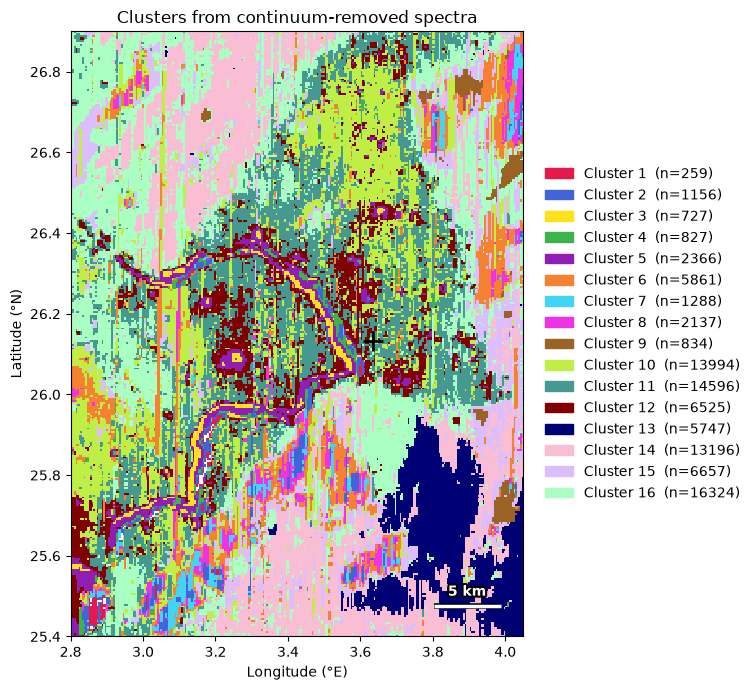

In [126]:
from matplotlib.colors import to_rgb

HIGH_CONTRAST = ["#e6194b",  # red
                 "#4363d8",  # blue
                 "#ffe119",  # yellow
                 "#3cb44b",  # green
                 "#911eb4",  # purple
                 "#f58231",  # orange
                 "#42d4f4",  # cyan
                 "#f032e6",  # magenta
                 "#9a6324",  # brown
                 "#bfef45",  # lime
                 "#469990",  # teal
                 "#800000",  # maroon
                 "#000075",  # navy
                 "#fabed4",  # pink
                 "#dcbeff",  # lavender
                 "#aaffc3"]  # mint

if k_cr > len(HIGH_CONTRAST):
    raise ValueError(f"Palette has {len(HIGH_CONTRAST)} colours but there are {k_cr} clusters")
colors_cr = [to_rgb(c) for c in HIGH_CONTRAST[:k_cr]]
cmap_cr = ListedColormap(colors_cr)
norm_cr = BoundaryNorm(np.arange(0.5, k_cr + 1.5), k_cr)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(label_img_cr, cmap=cmap_cr, norm=norm_cr, interpolation="nearest",
          extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
ax.plot(SITE_LON, SITE_LAT, "k+", ms=14, mew=2)
add_scalebar(ax, km=5)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title("Clusters from continuum-removed spectra")

sizes_cr = np.bincount(labels_cr, minlength=k_cr + 1)[1:]
handles = [Patch(color=colors_cr[i], label=f"Cluster {i + 1}  (n={sizes_cr[i]})")
           for i in range(k_cr)]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout(); plt.show()

In [128]:
import ipywidgets as widgets
from IPython.display import display

EXTENT = (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX)

boxes = [widgets.Checkbox(value=True, indent=False,
                          description=f"Cluster {i + 1}  (n={sizes_cr[i]})",
                          layout=widgets.Layout(width="190px"))
         for i in range(k_cr)]
alpha = widgets.FloatSlider(value=0.8, min=0.1, max=1.0, step=0.1,
                            description="Opacity", continuous_update=False,
                            layout=widgets.Layout(width="190px"))
btn_all = widgets.Button(description="Show all", layout=widgets.Layout(width="190px"))
btn_none = widgets.Button(description="Hide all", layout=widgets.Layout(width="190px"))

def set_all(value):
    for box in boxes:
        box.value = value
btn_all.on_click(lambda _: set_all(True))
btn_none.on_click(lambda _: set_all(False))

def draw(alpha, **ticks):
    shown = [i + 1 for i in range(k_cr) if ticks[f"c{i + 1}"]]
    img = np.where(np.isin(label_img_cr, shown), label_img_cr, np.nan)

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.imshow(cube_c[b_c], cmap="gray", vmin=0.03, vmax=0.20, extent=EXTENT)
    ax.imshow(img, cmap=cmap_cr, norm=norm_cr, interpolation="nearest",
              alpha=alpha, extent=EXTENT)
    ax.set_aspect(1 / np.cos(np.radians(SITE_LAT)))
    ax.plot(SITE_LON, SITE_LAT, "w+", ms=14, mew=2)
    add_scalebar(ax, km=5)
    ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
    ax.set_title("Clusters from continuum-removed spectra")
    handles = [Patch(color=colors_cr[c - 1], label=f"Cluster {c}  (n={sizes_cr[c - 1]})")
               for c in shown]
    if handles:
        ax.legend(handles=handles, loc="center left",
                  bbox_to_anchor=(1.02, 0.5), frameon=False)
    plt.tight_layout(); plt.show()

controls = {f"c{i + 1}": boxes[i] for i in range(k_cr)}
controls["alpha"] = alpha
out = widgets.interactive_output(draw, controls)

display(widgets.HBox([widgets.VBox([btn_all, btn_none, alpha] + boxes), out]))

In [ ]:
import ipywidgets as widgets
from IPython.display import display

# compute the statistics once, so toggling is instant
SOURCES = {"Continuum-removed reflectance": X_cr, "Reflectance": X}
stats = {name: [(data[labels_cr == i + 1].mean(axis=0),
                 data[labels_cr == i + 1].std(axis=0)) for i in range(k_cr)]
         for name, data in SOURCES.items()}

s_boxes = [widgets.Checkbox(value=True, indent=False,
                            description=f"Cluster {i + 1}  (n={sizes_cr[i]})",
                            layout=widgets.Layout(width="190px"))
           for i in range(k_cr)]
s_source = widgets.Dropdown(options=list(SOURCES), layout=widgets.Layout(width="190px"))
s_all = widgets.Button(description="Show all", layout=widgets.Layout(width="190px"))
s_none = widgets.Button(description="Hide all", layout=widgets.Layout(width="190px"))

def s_set_all(value):
    for box in s_boxes:
        box.value = value
s_all.on_click(lambda _: s_set_all(True))
s_none.on_click(lambda _: s_set_all(False))

def draw_spectra(source, **ticks):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for i in range(k_cr):
        if not ticks[f"c{i + 1}"]:
            continue
        mean, std = stats[source][i]
        ax.plot(wl_c, mean, color=colors_cr[i], lw=2,
                label=f"Cluster {i + 1}  (n={sizes_cr[i]})")
        ax.fill_between(wl_c, mean - std, mean + std, color=colors_cr[i], alpha=0.15)
    ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel(source)
    ax.set_title("Cluster spectra, continuum-removed clustering (mean ± 1 std)")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

s_controls = {f"c{i + 1}": s_boxes[i] for i in range(k_cr)}
s_controls["source"] = s_source
s_out = widgets.interactive_output(draw_spectra, s_controls)
display(widgets.HBox([widgets.VBox([s_all, s_none, s_source] + s_boxes), s_out]))

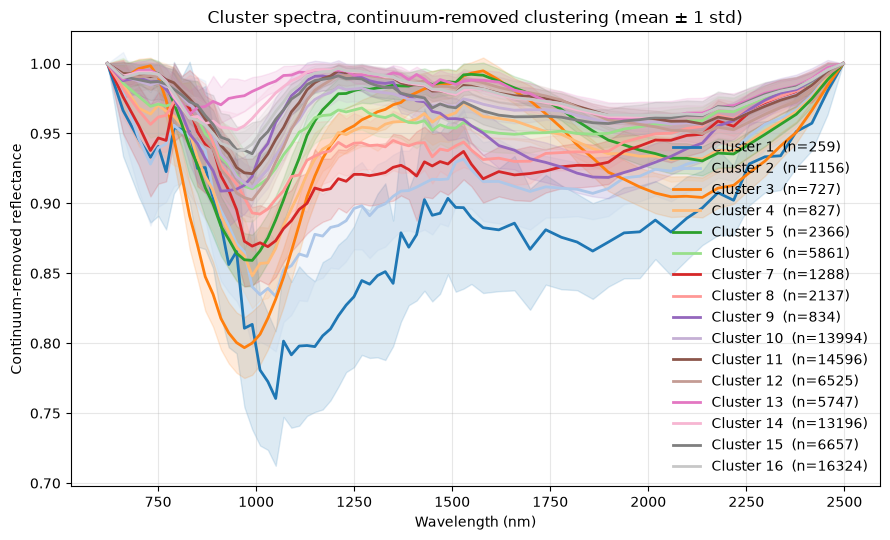

In [116]:
SPEC, YLABEL = X_cr, "Continuum-removed reflectance"   # or: X, "Reflectance"

fig, ax = plt.subplots(figsize=(9, 5.5))
for i in range(k_cr):
    spec = SPEC[labels_cr == i + 1]
    mean, std = spec.mean(axis=0), spec.std(axis=0)
    ax.plot(wl_c, mean, color=colors_cr[i], lw=2,
            label=f"Cluster {i + 1}  (n={len(spec)})")
    ax.fill_between(wl_c, mean - std, mean + std, color=colors_cr[i], alpha=0.15)

ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel(YLABEL)
ax.set_title("Cluster spectra, continuum-removed clustering (mean ± 1 std)")
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Denoise, destripe, and cluster again

# Denoise, destripe, and cluster again

In [56]:
from scipy.ndimage import median_filter, uniform_filter1d

PAD = 2000                                           # extra lines above and below the box
strip = subsets[0]["strip"]

with rasterio.open(find(strip, "LOC")) as src:
    lon, lat = src.read(1), src.read(2)
lon = ((lon + 180) % 360) - 180
in_box = (lat > LAT_MIN) & (lat < LAT_MAX) & (lon > LON_MIN) & (lon < LON_MAX)
rows = np.where(in_box.any(axis=1))[0]
r0, r1 = rows.min(), rows.max() + 1
w0, w1 = max(r0 - PAD, 0), min(r1 + PAD, lat.shape[0])

with rasterio.open(find(strip, "RFL")) as src:
    wide = src.read(window=Window(0, w0, src.width, w1 - w0)).astype("float32")
wide[wide < -900] = np.nan
nb, nl, ns = wide.shape
print(f"Statistics window: lines {w0}-{w1}  shape {wide.shape}")

b750 = np.argmin(np.abs(wl - 750))
dark = ~(wide[b750] > 0.02)                          # shadow / no-data, excluded from statistics
before = wide[:, r0 - w0:r1 - w0, :].copy()          # box subset before correction (for the check)

Statistics window: lines 10274-13822  shape (85, 3548, 304)


In [57]:
THRESH = 3.0                                         # flag columns this many times noisier than typical

bad = np.zeros((nb, ns), bool)
for i in range(nb):
    v = np.where(dark, np.nan, wide[i])
    if np.isnan(v).all():
        continue                                     # empty band (0 and 1)
    resid = v[:, 1:-1] - 0.5 * (v[:, :-2] + v[:, 2:])   # column minus mean of its neighbours
    noise = np.full(ns, np.nan)
    noise[1:-1] = np.nanstd(resid, axis=0)
    flagged = noise > THRESH * np.nanmedian(noise)
    # a bad column also inflates its two neighbours: keep only the local peak
    peak = (noise >= np.roll(noise, 1)) & (noise >= np.roll(noise, -1))
    bad[i] = flagged & peak

for i, c in zip(*np.where(bad)):
    print(f"bad element: band {i:2d} ({wl[i]:6.1f} nm), column {c}")
print("Total bad elements:", bad.sum())

cols = np.arange(ns)
for i in np.where(bad.any(axis=1))[0]:
    good = ~bad[i]
    for c in np.where(bad[i])[0]:
        l = cols[good & (cols < c)].max()            # nearest good column on each side
        r = cols[good & (cols > c)].min()
        wgt = (c - l) / (r - l)
        wide[i, :, c] = (1 - wgt) * wide[i, :, l] + wgt * wide[i, :, r]

bad element: band  3 ( 580.8 nm), column 160
bad element: band  9 ( 770.4 nm), column 200
bad element: band 10 ( 790.4 nm), column 294
bad element: band 15 ( 890.2 nm), column 272
bad element: band 24 (1069.8 nm), column 212
bad element: band 28 (1149.7 nm), column 197
Total bad elements: 6


## Destripe

In [58]:
PAD_LOCAL = 300                                      # lines above/below the box used for the fit
a0 = max(r0 - w0 - PAD_LOCAL, 0)
a1 = min(r1 - w0 + PAD_LOCAL, nl)
loc = wide[:, a0:a1, :]                              # view into `wide`, edited in place
dk = dark[a0:a1]

gains, offsets = np.ones((nb, ns)), np.zeros((nb, ns))
for i in range(nb):
    v = loc[i]
    if np.isnan(v).all():
        continue
    filled = np.where(np.isfinite(v), v, np.nanmedian(v))
    s = median_filter(filled, size=(1, 9), mode="nearest")   # stripe-free estimate, per line

    ok = ~dk & np.isfinite(v)                        # fit on sunlit, valid pixels only
    n_ok = np.maximum(ok.sum(axis=0), 1)
    sm = np.where(ok, s, 0).sum(axis=0) / n_ok
    vm = np.where(ok, v, 0).sum(axis=0) / n_ok
    cov = np.where(ok, (s - sm) * (v - vm), 0).sum(axis=0) / n_ok
    var = np.where(ok, (s - sm) ** 2, 0).sum(axis=0) / n_ok

    a = np.clip(cov / np.maximum(var, 1e-12), 0.8, 1.25)     # per-column gain
    o = vm - a * sm                                          # per-column offset
    loc[i] = (v - o) / a
    gains[i], offsets[i] = a, o

print(f"Gain spread (std), median over bands:   {np.median(gains.std(axis=1)) * 100:.2f}%")
print(f"Offset spread (std), median over bands: {np.median(offsets.std(axis=1)):.5f} reflectance")

if "rfl_original" not in subsets[0]:
    subsets[0]["rfl_original"] = subsets[0]["rfl"]
subsets[0]["rfl"] = wide[:, r0 - w0:r1 - w0, :].copy()

Gain spread (std), median over bands:   3.40%
Offset spread (std), median over bands: 0.00314 reflectance


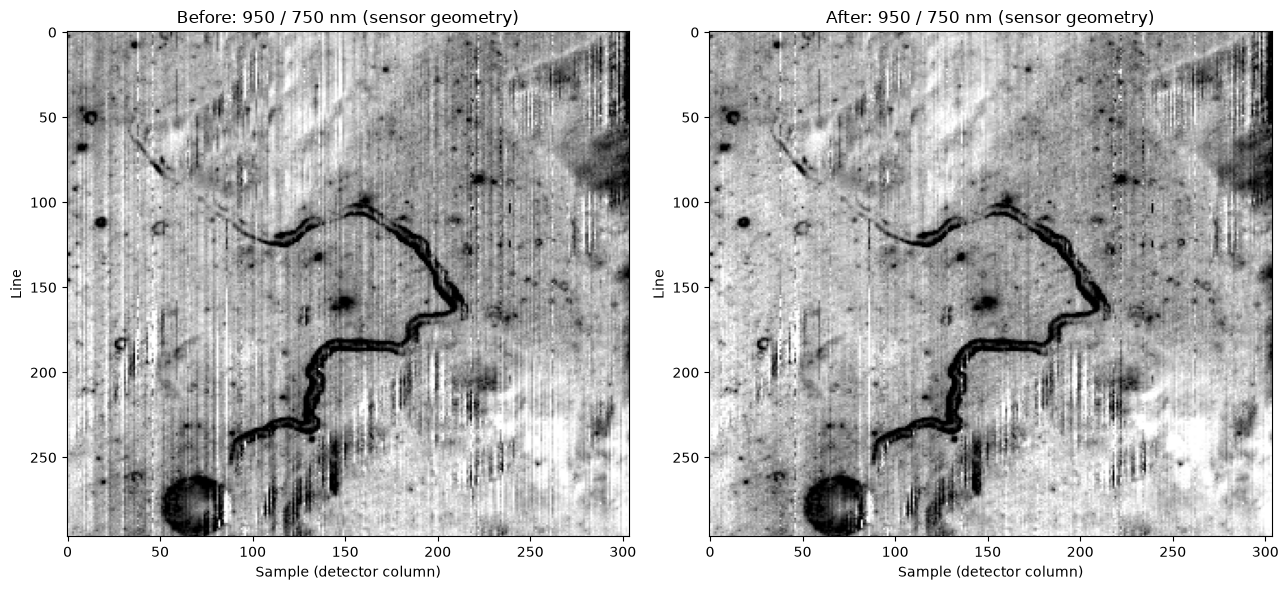

In [59]:
b950 = np.argmin(np.abs(wl - 950))
after = subsets[0]["rfl"]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, data, title in zip(axes, [before, after], ["Before", "After"]):
    ratio = data[b950] / data[b750]
    ax.imshow(ratio, cmap="gray", vmin=np.nanpercentile(ratio, 2),
              vmax=np.nanpercentile(ratio, 98), aspect="auto")
    ax.set_title(f"{title}: {wl[b950]:.0f} / {wl[b750]:.0f} nm (sensor geometry)")
    ax.set_xlabel("Sample (detector column)"); ax.set_ylabel("Line")
plt.tight_layout(); plt.show()

In [60]:
print("THRESH used:", THRESH, "| bad elements found:", bad.sum())
for i, c in zip(*np.where(bad)):
    print(f"  band {i:2d} ({wl[i]:6.1f} nm), column {c}")

# how noisy are the suspect columns in the two bands shown in the ratio image?
for i in (b750, b950):
    v = np.where(dark, np.nan, wide[i])
    resid = v[:, 1:-1] - 0.5 * (v[:, :-2] + v[:, 2:])
    noise = np.full(ns, np.nan); noise[1:-1] = np.nanstd(resid, axis=0)
    typical = np.nanmedian(noise)
    print(f"\nband {i} ({wl[i]:.0f} nm): typical column noise = {typical:.5f}")
    for c in range(40, 51):
        print(f"  col {c}: {noise[c] / typical:5.1f}x", end="")
    print()
    for c in range(215, 226):
        print(f"  col {c}: {noise[c] / typical:5.1f}x", end="")
    print()

THRESH used: 3.0 | bad elements found: 6
  band  3 ( 580.8 nm), column 160
  band  9 ( 770.4 nm), column 200
  band 10 ( 790.4 nm), column 294
  band 15 ( 890.2 nm), column 272
  band 24 (1069.8 nm), column 212
  band 28 (1149.7 nm), column 197

band 8 (750 nm): typical column noise = 0.00223
  col 40:   1.1x  col 41:   1.1x  col 42:   1.1x  col 43:   1.2x  col 44:   1.0x  col 45:   1.1x  col 46:   1.1x  col 47:   1.1x  col 48:   1.0x  col 49:   1.0x  col 50:   0.9x
  col 215:   1.0x  col 216:   0.9x  col 217:   1.0x  col 218:   1.1x  col 219:   1.1x  col 220:   0.9x  col 221:   1.0x  col 222:   1.0x  col 223:   1.0x  col 224:   0.9x  col 225:   0.9x

band 18 (950 nm): typical column noise = 0.00248
  col 40:   1.1x  col 41:   1.1x  col 42:   1.0x  col 43:   1.0x  col 44:   1.0x  col 45:   1.0x  col 46:   0.9x  col 47:   1.0x  col 48:   0.9x  col 49:   0.9x  col 50:   0.9x
  col 215:   1.0x  col 216:   1.0x  col 217:   1.0x  col 218:   0.9x  col 219:   0.9x  col 220:   0.9x  col 221:  